Installation et téléchargement données

In [1]:
!pip install wbgapi
import wbgapi as wb

import s3fs

fs = s3fs.S3FileSystem(client_kwargs={"endpoint_url": "https://minio.lab.sspcloud.fr"})

MY_BUCKET = "eleanorpaineau"
print(fs.ls(MY_BUCKET))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [wbgapi]

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
['eleanorpaineau/diffusion']


In [2]:
countries = ["AUS", "AUT", "BEL", "CAN", "CHL", "COL", "CRI", "CZE", "DNK", "EST", "FIN",
    "FRA", "DEU", "GRC", "HUN", "ISL", "IRL", "ISR", "ITA", "JPN", "KOR",
    "LVA", "LTU", "LUX", "MEX", "NLD", "NZL", "NOR", "POL", "PRT", "SVK",
    "SVN", "ESP", "SWE", "CHE", "TUR", "GBR", "USA"]
taux_chomage = wb.data.DataFrame("SL.UEM.TOTL.ZS", economy=countries , time=range(1991, 2024))
pib_hab_ppa = wb.data.DataFrame("NY.GDP.PCAP.PP.KD", economy=countries, time=range(1991, 2024))
rnb_hab_ppa = wb.data.DataFrame("NY.GNP.PCAP.PP.KD", economy=countries, time=range(1991, 2024))

with fs.open(f"{MY_BUCKET}/diffusion/projet/raw/wb_chomage.csv", "w") as f:
    taux_chomage.to_csv(f)
with fs.open(f"{MY_BUCKET}/diffusion/projet/raw/wb_pib_hab_ppa.csv", "w") as f:
    pib_hab_ppa.to_csv(f)
with fs.open(f"{MY_BUCKET}/diffusion/projet/raw/wb_rnb_hab_ppa.csv", "w") as f:
    rnb_hab_ppa.to_csv(f)


taux_chomage=taux_chomage.reset_index(names="economy")
pib_hab_ppa=pib_hab_ppa.reset_index(names="economy")
rnb_hab_ppa=rnb_hab_ppa.reset_index(names="economy")
print(pib_hab_ppa.tail(10))


   economy        YR1991        YR1992        YR1993        YR1994  \
28     NLD  43833.478505  44245.519825  44490.750447  45532.798666   
29     NOR  57949.698676  59669.759020  61019.816103  63730.896464   
30     NZL  29014.149942  29029.581136  30532.588017  31669.540651   
31     POL  11879.753925  12141.235132  12563.104536  13200.161416   
32     PRT  28443.794536  28776.047577  28153.615518  28348.865839   
33     SVK  14955.954208  13946.163079  14157.181437  14976.577355   
34     SVN  23078.992950  21850.057102  22524.959188  23752.437725   
35     SWE  39469.071647  38783.639768  37762.540822  39000.827723   
36     TUR  12057.935436  12451.045120  13174.467116  12343.004185   
37     USA  43747.630735  44664.873586  45292.738068  46543.319920   

          YR1995        YR1996        YR1997        YR1998        YR1999  ...  \
28  46720.281932  48095.986838  49881.894752  51879.359671  54134.351454  ...   
29  66033.883783  68964.975622  72084.813919  73610.189669  74703.5

Mise en forme - taux de chômage

In [3]:
import pandas as pd

# On transforme notre tableau afin que les colonnes des années deviennent des valeurs de la colonne "year"
df_taux_chomage=taux_chomage.melt(
    id_vars=["economy"],
    var_name="year",
    value_name="Taux chômage"
)

#Tri de notre tableau par ordre alphabétique des codes des pays 
df_taux_chomage=df_taux_chomage.sort_values(by="economy", ascending = True)

#Création d'un tableau qui associe les codes pays à leurs noms complets en anglais
noms = pd.DataFrame({
    "economy": ["AUS", "AUT", "BEL", "CAN", "CHL", "COL", "CRI", "CZE", "DNK", "EST", "FIN",
    "FRA", "DEU", "GRC", "HUN", "ISL", "IRL", "ISR", "ITA", "JPN", "KOR",
    "LVA", "LTU", "LUX", "MEX", "NLD", "NZL", "NOR", "POL", "PRT", "SVK",
    "SVN", "ESP", "SWE", "CHE", "TUR", "GBR", "USA"],

    "pays": ["Australia", "Austria", "Belgium", "Canada", "Chile", "Colombia", "Costa Rica",
    "Czechia", "Denmark", "Estonia", "Finland", "France", "Germany", "Greece",
    "Hungary", "Iceland", "Ireland", "Israel", "Italy", "Japan", "South Korea",
    "Latvia", "Lithuania", "Luxembourg", "Mexico", "Netherlands", "New Zealand",
    "Norway", "Poland", "Portugal", "Slovakia", "Slovenia", "Spain", "Sweden",
    "Switzerland", "Turkey", "United Kingdom", "United States"]
})
#On joint notre tableau pour ajouter les noms des pays, en regroupant par le code pays
df_taux_chomage=df_taux_chomage.merge(noms, on="economy", how="left")
print(df_taux_chomage.head(10))

  economy    year  Taux chômage       pays
0     AUS  YR1991         9.586  Australia
1     AUS  YR1992        10.733  Australia
2     AUS  YR1993        10.879  Australia
3     AUS  YR1994         9.724  Australia
4     AUS  YR1995         8.473  Australia
5     AUS  YR1996         8.509  Australia
6     AUS  YR1997         8.367  Australia
7     AUS  YR1998         7.684  Australia
8     AUS  YR1999         6.876  Australia
9     AUS  YR2000         6.288  Australia


Mise en forme - rnb/tête en ppa

In [21]:
# De la même manière, on transforme notre tableau afin que les années soient une variable de la colonne "year"
df_rnb_hab_ppa= rnb_hab_ppa.melt(
    id_vars=["economy"],
    var_name="year",
    value_name="RNB/tête PPA"
)

#Tri du tableau par ordre alphabétique des codes pays
df_rnb_hab_ppa=df_rnb_hab_ppa.sort_values(by="economy", ascending = True)

#Merge des tableaux avec taux de chômage et pib/hab ppa en faisant la jointure par pays et année
df_eco=df_taux_chomage.merge(df_rnb_hab_ppa, on=["economy", "year"], how="right")

print(df_eco['RNB/tête PPA'].count())

1117


Mise en forme - pib/tête en ppa

In [16]:
# De la même manière, on transforme notre tableau afin que les années soient une variable de la colonne "year"
df_pib_hab_ppa= pib_hab_ppa.melt(
    id_vars=["economy"],
    var_name="year",
    value_name="PIB/tête PPA"
)

#Tri du tableau par ordre alphabétique des codes pays
df_pib_hab_ppa=df_pib_hab_ppa.sort_values(by="economy", ascending = True)

#Merge des tableaux avec taux de chômage et pib/hab ppa en faisant la jointure par pays et année
df_eco=df_eco.merge(df_pib_hab_ppa, on=["economy", "year"], how="right")

#Pour que le tableau soit plus propre, on réorganise simplement les colonnes
df_eco = df_eco[["economy", "pays", "year", "Taux chômage", "RNB/tête PPA", "PIB/tête PPA"]]

#Transformation de la colonne "year" pour n'avoir que l'année et non "YRAAAA" (ex : "YR2004")
df_eco["year"]=df_eco["year"].str.replace("YR","")
print(df_eco.head(10))


  economy       pays  year  Taux chômage  RNB/tête PPA  PIB/tête PPA
0     AUS  Australia  1991         9.586  30292.797235  35670.667864
1     AUS  Australia  1992        10.733  30129.075368  35426.284829
2     AUS  Australia  1993        10.879  31003.190328  36533.146828
3     AUS  Australia  1994         9.724  31777.679986  37622.652477
4     AUS  Australia  1995         8.473  32639.871049  38653.336678
5     AUS  Australia  1996         8.509  33662.691064  39663.161773
6     AUS  Australia  1997         8.367  34875.303258  40773.566052
7     AUS  Australia  1998         7.684  36183.543200  42257.171812
8     AUS  Australia  1999         6.876  37251.745011  43899.073794
9     AUS  Australia  2000         6.288  38659.490992  45099.075210


Statistiques descriptives 

In [17]:
df_eco.describe(include="all")

,economy,pays,year,Taux chômage,RNB/tête PPA,PIB/tête PPA
count,1254,1254,1254,1254.000000,1117.000000,1254.000000
unique,38,38,33,NaN,NaN,NaN
top,AUS,Australia,1991,NaN,NaN,NaN
freq,33,33,38,NaN,NaN,NaN
mean,NaN,NaN,NaN,7.673285,43565.947871,43757.373618
std,NaN,NaN,NaN,4.096869,18481.545246,21762.823507
min,NaN,NaN,NaN,1.100000,9324.715700,9996.097860
25%,NaN,NaN,NaN,4.681750,30524.830297,28894.028201
50%,NaN,NaN,NaN,6.852000,43233.960087,42203.809597
75%,NaN,NaN,NaN,9.676250,54720.741199,54920.421745


Grâce au tableau des statistiques descriptives ci-dessus, on confirme que nos 38 pays sont bien représentés, nos 33 années de 1991 à 2023 le sont aussi. Il y a bien 38x33=1254 données pour le taux de chômage et le PIB/tête PPA : nos données sont complètes pour ces variables. Néanmoins nous n'avons que 1117 données pour le RNB/tête en PPA, il nous manque des données

Recherche des données manquantes :

In [9]:
print(df_eco.loc[df_eco['RNB/tête PPA'].isna(), ['economy', 'year']])

     economy    year
33       AUT  YR1991
34       AUT  YR1992
35       AUT  YR1993
36       AUT  YR1994
66       BEL  YR1991
...      ...     ...
1215     TUR  YR2018
1216     TUR  YR2019
1217     TUR  YR2020
1219     TUR  YR2022
1220     TUR  YR2023

[137 rows x 2 columns]


Répartition des données économiques d'intérêt

On représente la distribution des moyennes des variables, calculées par économie.

<Axes: >

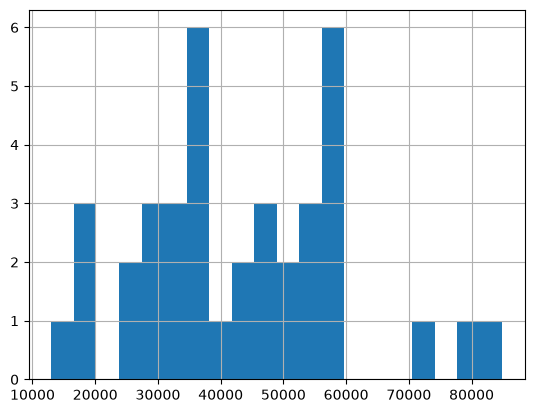

In [12]:
df_eco.groupby('economy')['RNB/tête PPA'].mean().hist(bins=20)

<Axes: >

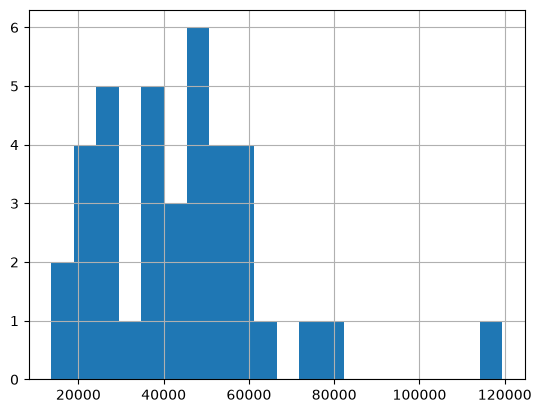

In [18]:
df_eco.groupby('economy')['PIB/tête PPA'].mean().hist(bins=20)

<Axes: >

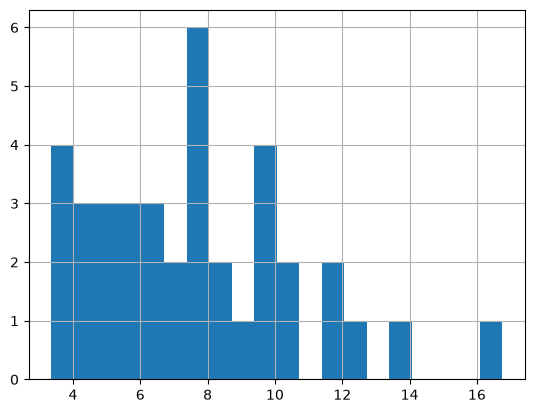

In [19]:
df_eco.groupby('economy')['Taux chômage'].mean().hist(bins=20)

On représente l'évolution de la moyenne annuelle de chaque variable.

<Axes: xlabel='year'>

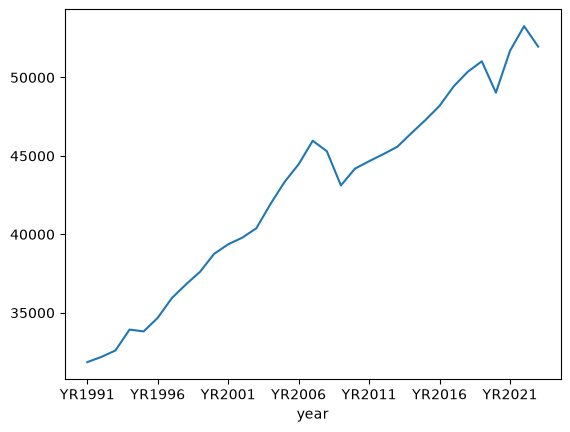

In [14]:
df_eco.groupby('year')['RNB/tête PPA'].mean().plot()

<Axes: xlabel='year'>

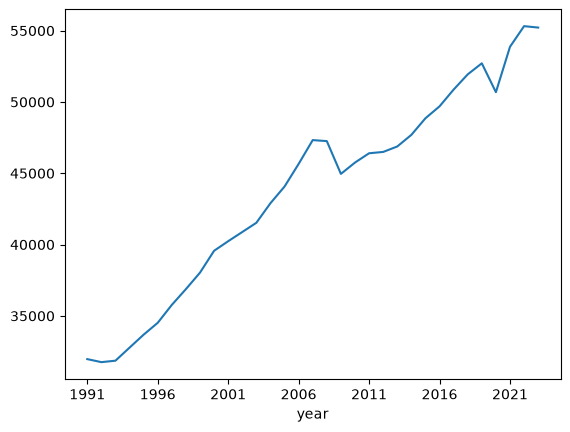

In [20]:
df_eco.groupby('year')['PIB/tête PPA'].mean().plot()

<Axes: xlabel='year'>

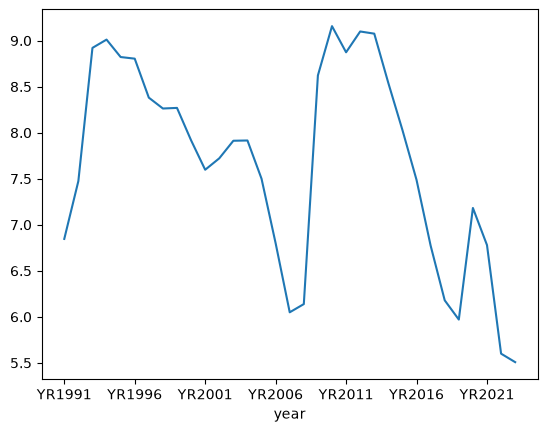

In [22]:
df_eco.groupby('year')['Taux chômage'].mean().plot()